# XRR fit: LSMO / STO (001), Parratt model

Model: **air | LSMO film | STO substrate**, Parratt recursion with Nevot-Croce roughness, plus a footprint correction at low angle.

To change the fit, edit the parameter table and the fit settings in section 2, then re-run sections 4 to 6. In the table, set `vary=False` to hold a parameter fixed, or change `value`, `min` and `max`.

## 1. Imports and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

WAVELENGTH = 1.540593  # Cu K-alpha1, Angstrom
CSV_FILE = 'XRR_LSMO_data.csv'

df = pd.read_csv(CSV_FILE)
df.columns = ['two_theta', 'intensity', 'atten']
tt = df['two_theta'].to_numpy()      # 2theta (deg)
I = df['intensity'].to_numpy()       # counts

## 2. Fit parameters and settings (edit here)

Lengths are in Angstrom. `delta` and `beta` are the real and imaginary parts of the refractive index, n = 1 - delta + i*beta, at Cu K-alpha. Starting values: LSMO delta about 1.8e-5, STO delta about 1.5e-5.

In [2]:
PARAMS = {
    'thickness':     dict(value=360.0,   min=200.0,  max=500.0,  vary=True),   # LSMO thickness (A)
    'delta_film':    dict(value=18e-6,   min=8e-6,   max=25e-6,  vary=True),   # LSMO delta
    'beta_film':     dict(value=1.5e-6,  min=0.1e-6, max=5e-6,   vary=True),   # LSMO beta
    'rough_surf':    dict(value=10.0,    min=0.0,    max=40.0,   vary=True),   # air / LSMO roughness (A)
    'rough_int':     dict(value=5.0,     min=0.0,    max=30.0,   vary=True),   # LSMO / STO roughness (A)
    'delta_sub':     dict(value=15e-6,   min=10e-6,  max=18e-6,  vary=False),  # STO delta
    'beta_sub':      dict(value=0.73e-6, min=0.1e-6, max=3e-6,   vary=False),  # STO beta
    'log10_I0':      dict(value=6.5,     min=5.0,    max=8.0,    vary=True),   # log10 of intensity scale
    'bg':            dict(value=0.5,     min=0.0,    max=5.0,    vary=False),  # constant background (counts)
    'footprint_2th': dict(value=0.5,     min=0.2,    max=1.5,    vary=True),   # 2theta below which the beam overfills the sample (deg)
    'tt_offset':     dict(value=0.0,     min=-0.1,   max=0.1,    vary=False),  # zero-angle offset (deg)
}

# Fit settings
FIT_MIN_2TH = 0.3                          # fit range, 2theta (deg)
FIT_MAX_2TH = 3.6
MIN_COUNTS = 5                             # ignore points below this (noise floor)
START_THICKNESSES = [300, 340, 380, 420]   # multi-start values for thickness (A); the best result is kept

## 3. Model

In [3]:
def parratt(theta_deg, deltas, betas, thick, sigmas):
    '''Reflectivity of a layer stack: ambient, layers..., substrate.
    thick: layer thicknesses in A (first and last entries are ignored).
    sigmas: roughness of each interface (Nevot-Croce), length = number of layers - 1.'''
    th = np.radians(theta_deg)
    k = 2 * np.pi / WAVELENGTH
    n = 1 - np.array(deltas) + 1j * np.array(betas)
    kz = k * np.sqrt(n[:, None] ** 2 - np.cos(th)[None, :] ** 2 + 0j)
    N = len(n)
    X = np.zeros(len(th), dtype=complex)
    for j in range(N - 2, -1, -1):
        r = (kz[j] - kz[j + 1]) / (kz[j] + kz[j + 1]) * np.exp(-2 * kz[j] * kz[j + 1] * sigmas[j] ** 2)
        ph = np.exp(2j * kz[j + 1] * thick[j + 1]) if j + 1 < N - 1 else 0
        X = (r + X * ph) / (1 + r * X * ph)
    return np.abs(X) ** 2


def model_intensity(two_theta, p):
    '''Simulated counts for a dict of parameter values p.'''
    theta = (two_theta + p['tt_offset']) / 2
    R = parratt(theta,
                deltas=[0, p['delta_film'], p['delta_sub']],
                betas=[0, p['beta_film'], p['beta_sub']],
                thick=[0, p['thickness'], 0],
                sigmas=[p['rough_surf'], p['rough_int']])
    # footprint: below the angle where the beam fits on the sample, intensity drops as sin(theta)
    foot = np.minimum(1, np.sin(np.radians(theta)) / np.sin(np.radians(p['footprint_2th'] / 2)))
    return 10 ** p['log10_I0'] * R * foot + p['bg']

## 4. Fit function

Least squares on log10(counts), so the fringes at low and high intensity carry equal weight.

In [4]:
def get_values(params):
    return {k: v['value'] for k, v in params.items()}


def run_fit(params, start_thicknesses):
    free = [k for k, v in params.items() if v['vary']]
    lo = np.array([params[k]['min'] for k in free], float)
    hi = np.array([params[k]['max'] for k in free], float)
    mask = (tt >= FIT_MIN_2TH) & (tt <= FIT_MAX_2TH) & (I > MIN_COUNTS)

    def resid(x):
        p = get_values(params)
        p.update(dict(zip(free, x)))
        return np.log10(model_intensity(tt[mask], p)) - np.log10(I[mask])

    starts = start_thicknesses if 'thickness' in free else [params['thickness']['value']]
    best = None
    for t0 in starts:
        x0 = np.array([params[k]['value'] for k in free], float)
        if 'thickness' in free:
            x0[free.index('thickness')] = t0
        x0 = np.clip(x0, lo, hi)
        res = least_squares(resid, x0, bounds=(lo, hi), x_scale=np.maximum(np.abs(x0), 1e-6))
        if best is None or res.cost < best.cost:
            best = res
    return free, best, mask

## 5. Run the fit and print the results

In [5]:
free, res, mask = run_fit(PARAMS, START_THICKNESSES)

n_pts, n_par = mask.sum(), len(free)
s2 = 2 * res.cost / (n_pts - n_par)                 # variance of residuals (log10 units)
cov = np.linalg.pinv(res.jac.T @ res.jac) * s2
err = np.sqrt(np.diag(cov))

fitted = get_values(PARAMS)
fitted.update(dict(zip(free, res.x)))

rows = []
for k in PARAMS:
    if k in free:
        i = free.index(k)
        at_bound = np.isclose(res.x[i], PARAMS[k]['min']) or np.isclose(res.x[i], PARAMS[k]['max'])
        rows.append([k, fitted[k], err[i], 'fitted' + (' (AT BOUND)' if at_bound else '')])
    else:
        rows.append([k, fitted[k], np.nan, 'fixed'])
table = pd.DataFrame(rows, columns=['parameter', 'value', '1-sigma error', 'status'])
print(table.to_string(index=False))

print()
print(f"Thickness = {fitted['thickness'] / 10:.2f} nm")
print(f"rms residual = {np.sqrt(s2):.3f} (log10 counts), {n_pts} points, {n_par} free parameters")
print(f"film delta / bulk LSMO delta (1.82e-5) = {fitted['delta_film'] / 1.82e-5:.2f}")

    parameter        value  1-sigma error status
    thickness 3.505733e+02   2.077727e-01 fitted
   delta_film 1.834753e-05   2.137630e-07 fitted
    beta_film 2.525692e-06   1.931919e-07 fitted
   rough_surf 7.807864e+00   3.850420e-02 fitted
    rough_int 4.980545e+00   2.015522e-01 fitted
    delta_sub 1.500000e-05            NaN  fixed
     beta_sub 7.300000e-07            NaN  fixed
     log10_I0 6.548819e+00   1.492875e-02 fitted
           bg 5.000000e-01            NaN  fixed
footprint_2th 4.439039e-01   2.425589e-02 fitted
    tt_offset 0.000000e+00            NaN  fixed

Thickness = 35.06 nm
rms residual = 0.076 (log10 counts), 328 points, 7 free parameters
film delta / bulk LSMO delta (1.82e-5) = 1.01


## 6. Plot data, fit and residuals

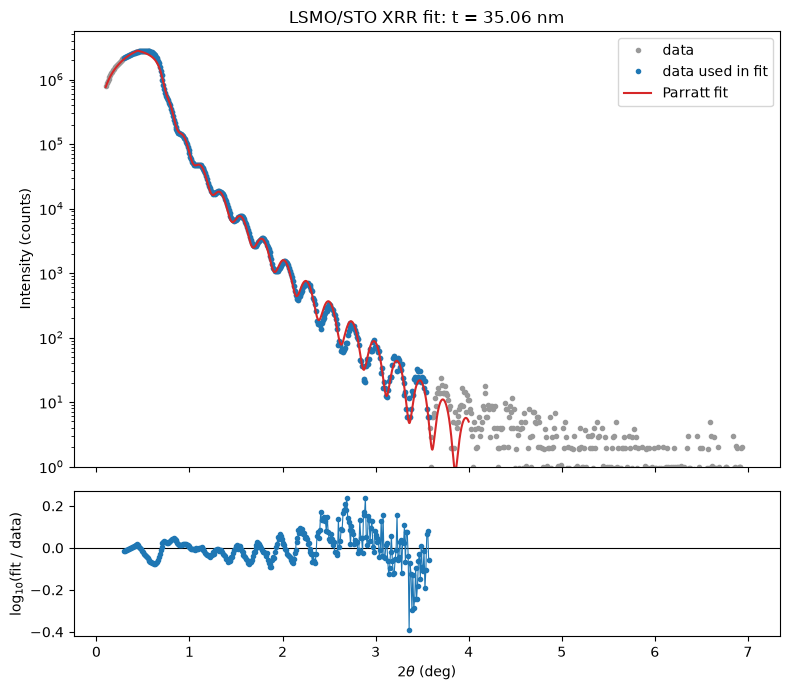

In [6]:
tt_fine = np.linspace(tt.min(), FIT_MAX_2TH + 0.4, 1500)
sim = model_intensity(tt_fine, fitted)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})

ax1.semilogy(tt, np.clip(I, 0.5, None), 'o', ms=3, color='0.6', label='data')
ax1.semilogy(tt[mask], I[mask], 'o', ms=3, color='C0', label='data used in fit')
ax1.semilogy(tt_fine, sim, '-', color='C3', lw=1.5, label='Parratt fit')
ax1.set_ylabel('Intensity (counts)')
ax1.set_ylim(1, 2 * I.max())
ax1.set_title(f"LSMO/STO XRR fit: t = {fitted['thickness'] / 10:.2f} nm")
ax1.legend()

resid = np.log10(model_intensity(tt[mask], fitted)) - np.log10(I[mask])
ax2.axhline(0, color='k', lw=0.8)
ax2.plot(tt[mask], resid, '.-', lw=0.8, color='C0')
ax2.set_xlabel(r'2$\theta$ (deg)')
ax2.set_ylabel(r'log$_{10}$(fit / data)')

plt.tight_layout()
plt.show()